# Assessment 1: Chicago Food Inspection Data Analysis

**Exploratory data analysis, data quality and modelling plan**

The task is to predict whether an inspection will Fail using information available before the visit. A row is an inspection, so a business can appear repeatedly. Results defines the target: Fail = 1; Pass and Pass w/ Conditions = 0. Out of Business, No Entry, Not Ready and Business Not Located have no binary judgement and remain useful as earlier history.

This notebook uses the saved public snapshot downloaded on **2026-10-12**, with inspection dates **2016-01-04 to 2026-10-09**. Substantive outcome analysis uses **2016-2025**. The 2026 period is reserved for later local evaluation. Earlier preparation checked labels across the file; the proposed local holdout is retrospective, rather than prospectively unseen data. No local-test performance is calculated here.

The notebook reads saved raw data and local helper code, works offline, and writes eight figures and supporting tables. Run All from the repository root or the notebooks directory. Python dependencies are listed in requirements.txt; no install or download occurs during execution.

## 1. Reproducible setup and source checks

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
import textwrap

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "config/data.json").is_file() and (p / "scripts/ass1_utils.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Start this notebook from inside the project repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "tmp/matplotlib"))
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, FuncFormatter
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from ass1_utils import load_snapshot, clean_history, group_rates, strict_past_features
from prepare_data import RAW_TO_CLEAN

CFG = json.loads((ROOT / "config/assessment1.json").read_text(encoding="utf-8"))
DEV_END = pd.Timestamp(CFG["development_end"])
np.random.seed(CFG["random_seed"])
OUT = ROOT / "reports/assessment1"
FIG = ROOT / "reports/figures/assessment1"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_colwidth", 100)

NAVY, TEAL, RUST, GREY = "#29465B", "#238B83", "#C56B4C", "#9CA8B0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.facecolor": "white", "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#D0D7DD", "axes.labelcolor": NAVY,
    "text.color": NAVY, "xtick.color": NAVY, "ytick.color": NAVY,
    "grid.color": "#E9EDF0", "grid.linewidth": .7,
})
figure_paths = []

def save_figure(fig, filename):
    fig.savefig(FIG / filename, bbox_inches="tight", facecolor="white")
    figure_paths.append(filename)
    plt.show()
    plt.close(fig)

def save_table(frame, name, index=True):
    frame.to_csv(OUT / name, index=index, lineterminator="\n")

def rate_plot(ax, rates, color=TEAL, baseline=None, xmax=None, wrap=25):
    y = np.arange(len(rates))
    rate = rates["rate"].to_numpy(dtype=float)
    low = rates["low"].to_numpy(dtype=float)
    high = rates["high"].to_numpy(dtype=float)
    ax.errorbar(rate, y, xerr=np.maximum(0, np.vstack([rate-low, high-rate])),
                fmt="o", color=color, ecolor=color, capsize=3, markersize=5, linewidth=1.3)
    labels = [f"{textwrap.fill(str(name).title().replace("'S", "'s"), wrap)}\n(n={int(n):,})"
              for name, n in zip(rates.index, rates["n"])]
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    right = xmax or max(.35, float(rates["high"].max()) * 1.25)
    ax.set_xlim(0, right)
    for position, value in enumerate(rate):
        ax.text(right*.985, position, f"{value:.1%}", ha="right", va="center", fontsize=9)
    if baseline is not None:
        ax.axvline(baseline, color=GREY, linestyle="--", linewidth=1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Fail / labelled inspections")
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)


Python 3.13.1 | pandas 3.0.6 | numpy 2.5.4


In [2]:
raw, raw_dates, metadata = load_snapshot(ROOT)
assert metadata["csv_sha256"] == CFG["snapshot_sha256"], (
    "This narrative is tied to the frozen Assessment 1 snapshot. "
    "A refreshed snapshot requires checking and updating the written findings."
)
history, normalization_counts = clean_history(raw)
dev_raw = raw.loc[raw_dates.le(DEV_END)].copy()
dev = history.loc[history["inspection_date"].le(DEV_END)].copy()
labelled = dev.loc[dev["label"].notna()].copy()
assert set(labelled["label"].unique()) == {0, 1}
assert history["inspection_id"].is_unique
assert dev["inspection_date"].max() <= DEV_END

snapshot = pd.DataFrame([
    ("Dataset", metadata["dataset_id"]),
    ("Source", metadata["portal_page"]),
    ("Download time, UTC", metadata["downloaded_at_utc"]),
    ("Requested window", f'{metadata["requested_window"]["start_date"]} to {metadata["requested_window"]["end_date"]}'),
    ("Actual inspection range", f'{raw_dates.min().date()} to {raw_dates.max().date()}'),
    ("Full snapshot rows", len(raw)),
    ("EDA rows, 2016-2025", len(dev)),
    ("Labelled EDA rows", len(labelled)),
    ("EDA records without binary judgement", len(dev)-len(labelled)),
    ("Repeated raw Inspection IDs", int(raw["Inspection ID"].duplicated().sum())),
    ("Fully duplicated raw rows", int(raw.duplicated().sum())),
    ("SHA-256, compressed raw CSV", metadata["csv_sha256"]),
], columns=["item", "value"])
display(snapshot)
save_table(snapshot, "snapshot.csv", index=False)
schema = pd.DataFrame({
    "raw_field": raw.columns,
    "raw_dtype": [str(raw[c].dtype) for c in raw.columns],
    "clean_field": [RAW_TO_CLEAN[c] for c in raw.columns],
    "clean_dtype": [
        str(history[RAW_TO_CLEAN[c]].dtype) if RAW_TO_CLEAN[c] in history else "excluded from candidate inputs"
        for c in raw.columns
    ],
})
display(schema)
save_table(schema, "schema.csv", index=False)


,item,value
0,Dataset,4ijn-s7e5
1,Source,https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5
2,"Download time, UTC",2026-10-12T07:59:09+00:00
3,Requested window,2016-01-01 to 2026-10-12
4,Actual inspection range,2016-01-04 to 2026-10-09
5,Full snapshot rows,197882
6,"EDA rows, 2016-2025",185270
7,Labelled EDA rows,156822
8,EDA records without binary judgement,28448
9,Repeated raw Inspection IDs,0


,raw_field,raw_dtype,clean_field,clean_dtype
0,Inspection ID,string,inspection_id,str
1,DBA Name,string,dba_name,str
2,AKA Name,string,aka_name,str
3,License #,string,license_number,str
4,Facility Type,string,facility_type,str
5,Risk,string,risk,str
6,Address,string,address,str
7,City,string,city,str
8,State,string,state,str
9,Zip,string,zip,str


The raw fields are loaded as strings to preserve identifiers and ZIP codes. Dates are parsed explicitly as MM/DD/YYYY, and the cleaned date is a datetime value. Coordinates are numeric; label and risk_level are nullable integers. Cleaning reuses the local preparation rules: trim whitespace, standardize category case, keep missing static categories as UNKNOWN, and retain legitimate repeated visits. It does not fit an imputer, scaler or encoder on the full dataset.

All 17 raw fields remain in the saved source. The analysis table omits the long Violations text and redundant Location string. Its violations_missing flag is used only to audit reporting and leakage, never as a candidate input. Store matching uses valid licence numbers, then a name/address fallback. These are provisional identities, not verified business entities.

## 2. Outcomes, denominators and class imbalance

**Question:** How many records have a valid target, and why is accuracy insufficient?

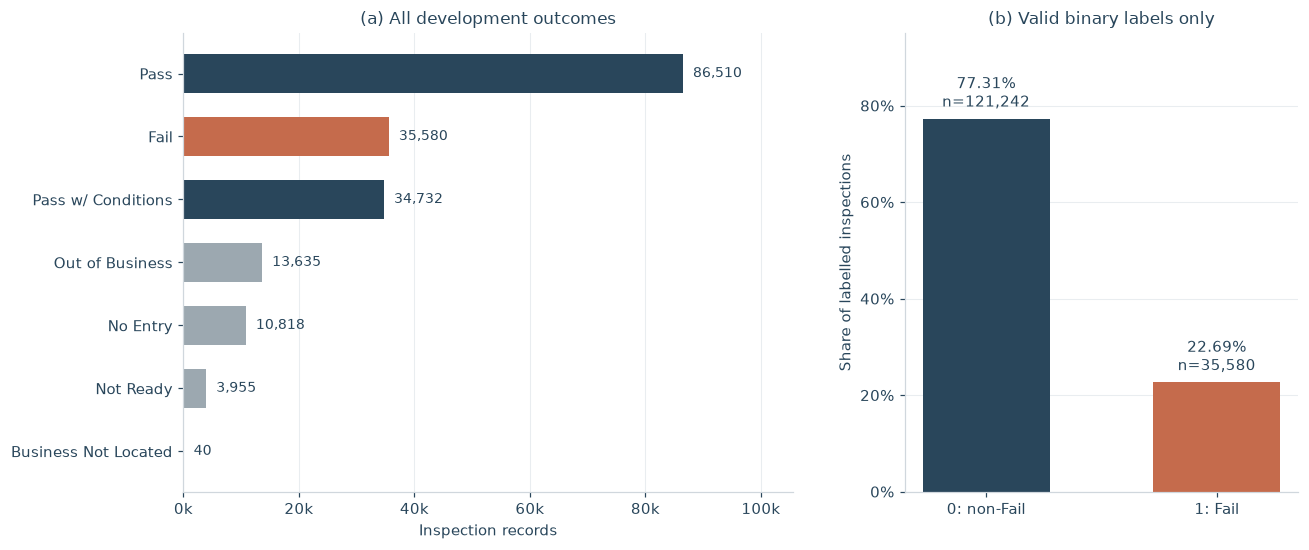

Descriptive constant-prediction example, not a held-out score: accuracy=0.7731; Macro-F1=0.4360


In [3]:
result_counts = dev["results"].value_counts()
class_counts = labelled["label"].value_counts().reindex([0, 1])
overall_rate = float(labelled["label"].mean())
excluded_rows = len(dev) - len(labelled)
result_table = result_counts.rename("rows").to_frame()
result_table["use"] = [
    "label 1" if value == "Fail" else
    "label 0" if value in {"Pass", "Pass w/ Conditions"} else "history only"
    for value in result_table.index
]
save_table(result_table, "outcome_counts.csv")
save_table(class_counts.rename("rows").to_frame(), "class_counts.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 5.1), gridspec_kw={"width_ratios": [1.55, 1]})
colors = [RUST if value == "Fail" else NAVY if value in {"Pass", "Pass w/ Conditions"} else GREY
          for value in result_counts.index]
axes[0].barh(np.arange(len(result_counts)), result_counts.values, color=colors, height=.62)
axes[0].set_yticks(np.arange(len(result_counts)), result_counts.index)
axes[0].invert_yaxis()
for y, count in enumerate(result_counts):
    axes[0].text(count + result_counts.max()*.02, y, f"{count:,}", va="center", fontsize=9)
axes[0].set_xlim(0, result_counts.max()*1.22)
axes[0].set_title("(a) All development outcomes")
axes[0].set_xlabel("Inspection records")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value/1000:g}k"))
axes[0].xaxis.grid(True)
axes[0].set_axisbelow(True)
shares = class_counts / class_counts.sum()
axes[1].bar(["0: non-Fail", "1: Fail"], shares.values, color=[NAVY, RUST], width=.55)
for x, (count, share) in enumerate(zip(class_counts, shares)):
    axes[1].text(x, share+.025, f"{share:.2%}\nn={count:,}", ha="center", fontsize=10)
axes[1].set_ylim(0, .95)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_ylabel("Share of labelled inspections")
axes[1].set_title("(b) Valid binary labels only")
axes[1].yaxis.grid(True)
axes[1].set_axisbelow(True)
fig.tight_layout(w_pad=3)
save_figure(fig, "01_outcomes_and_labels.png")
always_nonfail_macro_f1 = (1-overall_rate) / (2-overall_rate)
print(f"Descriptive constant-prediction example, not a held-out score: "
      f"accuracy={1-overall_rate:.4f}; Macro-F1={always_nonfail_macro_f1:.4f}")


**Figure 1.** Of 185,270 development records, **156,822** have a binary judgement and **28,448** remain history-only records. Fail accounts for **35,580 / 156,822 = 22.69%**. Predicting non-Fail for every development record with a label would achieve 77.31% accuracy but only about 0.436 Macro-F1, because the Fail-class F1 would be zero. This is a descriptive illustration, not a model evaluation. The model-selection metric will be Macro-F1, with both class-specific error rates reported.

Treating No Entry or Out of Business as a pass would change both the target and the denominator. Their occurrence can still contribute to earlier visit counts.

## 3. Changes over time

**Question:** Are inspection volume and the observed failure rate stable enough to justify a random split?

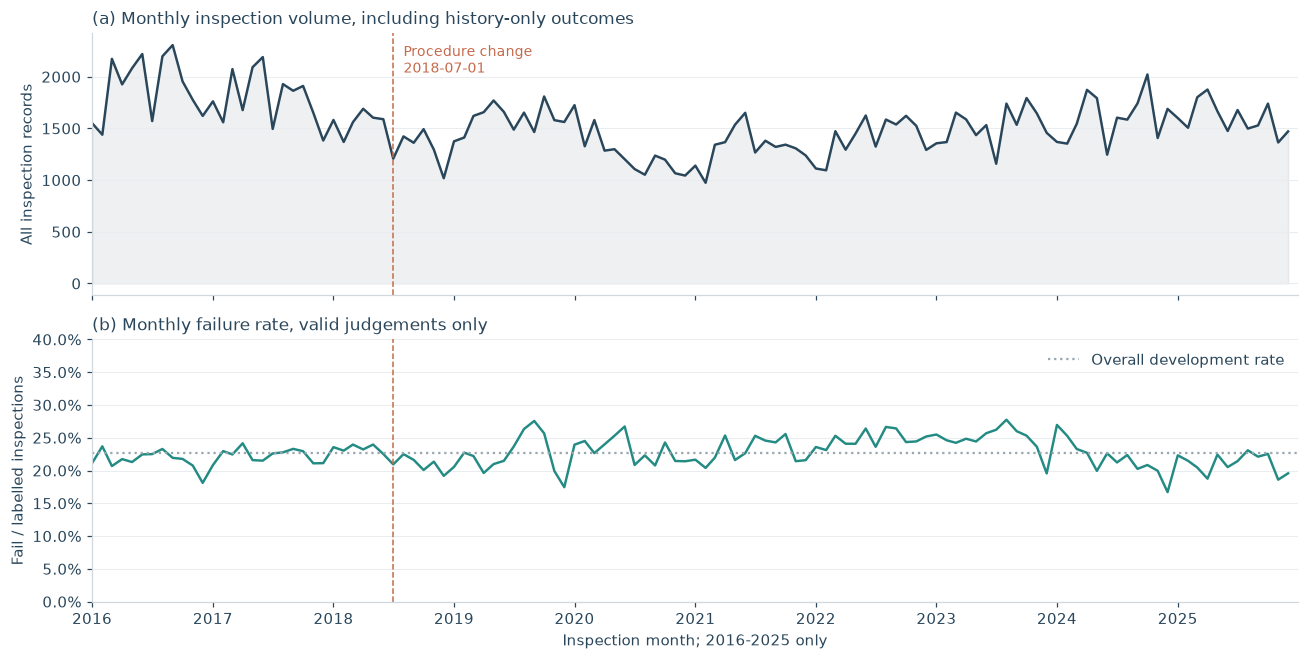

,inspections,labelled,failures,fail_rate
inspection_year,,,,
2016,22818,19860,4298,0.216415
2017,21587,18499,4121,0.222769
2018,17192,14849,3318,0.223449
2019,19052,16121,3612,0.224056
2020,15123,12600,2935,0.232937
2021,15868,13139,3035,0.230992
2022,16936,14286,3554,0.248775
2023,18261,15413,3835,0.248816
2024,19228,15995,3481,0.217631


In [4]:
monthly = dev.resample("MS", on="inspection_date").agg(
    inspections=("inspection_id", "size"), labelled=("label", "count"), failures=("label", "sum")
)
monthly["fail_rate"] = (monthly["failures"] / monthly["labelled"]).astype(float)
annual = dev.groupby("inspection_year").agg(
    inspections=("inspection_id", "size"), labelled=("label", "count"), failures=("label", "sum")
)
annual["fail_rate"] = (annual["failures"] / annual["labelled"]).astype(float)
save_table(monthly, "monthly_counts_and_rates.csv")
save_table(annual, "annual_counts_and_rates.csv")
fig, axes = plt.subplots(2, 1, figsize=(12, 6.1), sharex=True)
axes[0].plot(monthly.index, monthly.inspections, color=NAVY, linewidth=1.6)
axes[0].fill_between(monthly.index, monthly.inspections, color=NAVY, alpha=.08)
axes[0].set_ylabel("All inspection records")
axes[0].set_title("(a) Monthly inspection volume, including history-only outcomes", loc="left")
axes[1].plot(monthly.index, monthly.fail_rate, color=TEAL, linewidth=1.6)
axes[1].axhline(overall_rate, color=GREY, linestyle=":", label="Overall development rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_ylabel("Fail / labelled inspections")
axes[1].set_ylim(0, max(.4, float(monthly.fail_rate.max())+.04))
axes[1].set_title("(b) Monthly failure rate, valid judgements only", loc="left")
for ax in axes:
    ax.axvline(pd.Timestamp("2018-07-01"), color=RUST, linestyle="--", linewidth=1)
    ax.grid(axis="y")
axes[0].text(pd.Timestamp("2018-08-01"), .96, "Procedure change\n2018-07-01",
             transform=axes[0].get_xaxis_transform(), va="top", fontsize=9, color=RUST)
axes[1].legend(frameon=False, loc="upper right")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].set_xlabel("Inspection month; 2016-2025 only")
axes[1].set_xlim(pd.Timestamp("2016-01-01"), DEV_END)
fig.tight_layout()
save_figure(fig, "02_time_volume_and_rates.png")
display(annual)


**Figure 2.** Recorded volume fell from **19,052 in 2019 to 15,123 in 2020**, a 20.6% decrease. The annual Fail rate was **24.88% in 2023** and **21.11% in 2025**, so a fixed historical class balance would not describe every year. These are changes in inspected records, not estimates of all establishments' underlying food-safety risk.

The saved portal metadata notes a procedure change on **2018-07-01**, marked by the dashed line. The chart alone does not identify why counts or rates changed. Calendar-time features and forward validation are justified; randomly mixing years would conceal this deployment shift. Partial 2026 data are excluded from this outcome comparison.

## 4. Missing values and information available at prediction time

**Question:** Which gaps affect data preparation, and which fields are produced by the inspection itself?

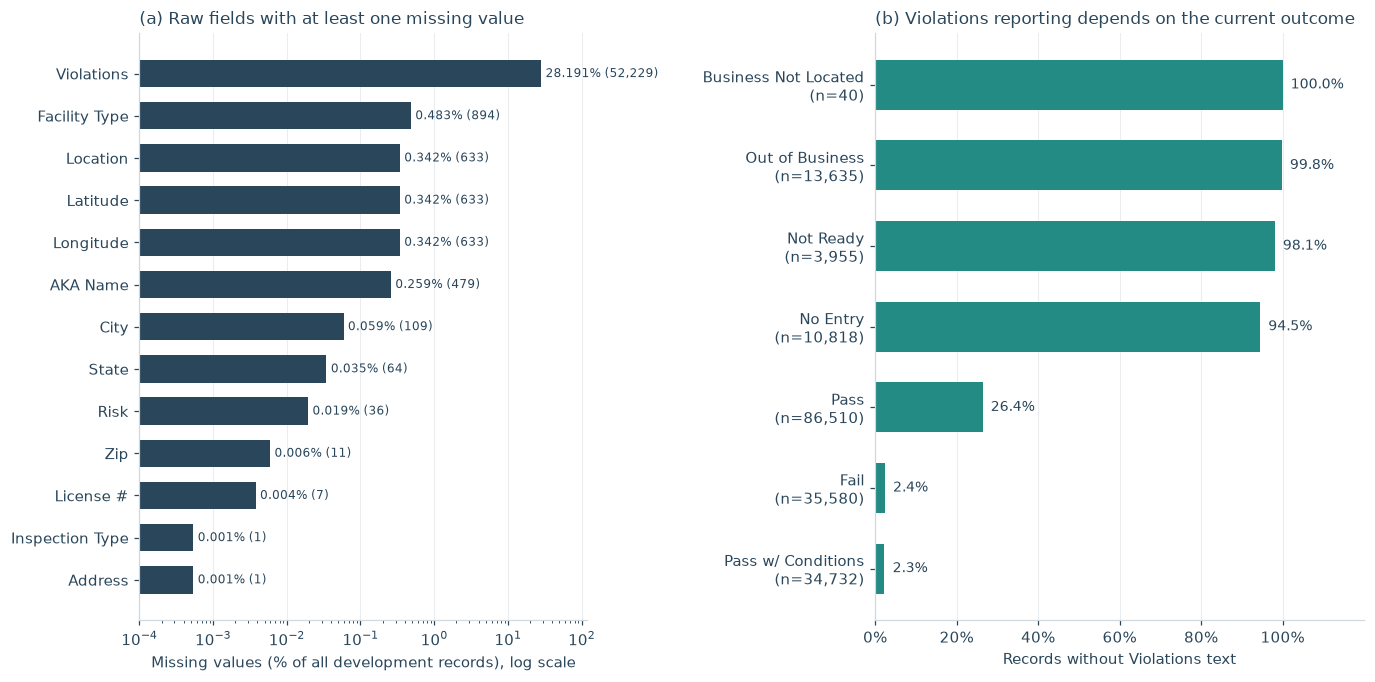

,missing_count,missing_percent
Violations,52229,28.190749
Facility Type,894,0.482539
Longitude,633,0.341664
Location,633,0.341664
Latitude,633,0.341664
AKA Name,479,0.258542
City,109,0.058833
State,64,0.034544
Risk,36,0.019431
Zip,11,0.005937


In [5]:
missing = pd.DataFrame({
    "missing_count": {column: int(dev_raw[column].str.fullmatch(r"\s*", na=True).sum())
                      for column in dev_raw.columns}
})
missing["missing_percent"] = 100 * missing["missing_count"] / len(dev_raw)
save_table(missing, "missing_values_development.csv")
violation_gaps = dev.groupby("results")["violations_missing"].agg(n="size", missing_rate="mean")
save_table(violation_gaps, "violations_missing_by_outcome.csv")

fig, axes = plt.subplots(1, 2, figsize=(12.6, 6.3), gridspec_kw={"width_ratios": [1.1, 1.2]})
nonzero = missing.loc[missing.missing_count.gt(0)].sort_values("missing_percent")
axes[0].barh(nonzero.index, nonzero.missing_percent, color=NAVY, height=.65)
axes[0].set_xscale("log")
axes[0].set_xlim(.0001, 120)
for y, (percent, count) in enumerate(zip(nonzero.missing_percent, nonzero.missing_count)):
    axes[0].text(percent*1.15, y, f"{percent:.3f}% ({count:,})", va="center", fontsize=8)
axes[0].set_xlabel("Missing values (% of all development records), log scale")
axes[0].set_title("(a) Raw fields with at least one missing value", loc="left")
axes[0].xaxis.grid(True, which="major")
axes[0].set_axisbelow(True)
gap_order = violation_gaps.sort_values("missing_rate")
axes[1].barh(np.arange(len(gap_order)), gap_order.missing_rate, color=TEAL, height=.62)
axes[1].set_yticks(np.arange(len(gap_order)), [
    f"{name}\n(n={row['n']:,.0f})" for name, row in gap_order.iterrows()
])
for y, value in enumerate(gap_order.missing_rate):
    axes[1].text(value+.02, y, f"{value:.1%}", va="center", fontsize=9)
axes[1].set_xlim(0, 1.20)
axes[1].set_xticks(np.linspace(0, 1, 6))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xlabel("Records without Violations text")
axes[1].set_title("(b) Violations reporting depends on the current outcome", loc="left")
axes[1].xaxis.grid(True)
axes[1].set_axisbelow(True)
fig.tight_layout(w_pad=3)
save_figure(fig, "03_missingness_and_leakage.png")
display(missing.sort_values("missing_percent", ascending=False))


**Figure 3.** Violations is missing in **52,229 development records (28.19%)**. Missingness is outcome-dependent: **26.38% of Pass** records lack this text, compared with **2.40% of Fail** records, and almost all Out of Business records. Missing text therefore cannot be treated as a pre-visit indicator of safety. Both the current Violations text and its missingness flag are unavailable as model inputs.

Static-field gaps are much smaller: **894 Facility Type**, **36 Risk**, **7 License #**, and **633 coordinate pairs** are missing. A fixed UNKNOWN category preserves missing categorical information. Numeric imputation, missingness indicators and category-frequency rules will be learned from training data only. A zero licence is also invalid despite not being blank; this is examined in the quality table.

## 5. Facility type and recorded risk

**Question:** Do the available business categories separate failure rates, and does a higher recorded risk category imply a higher observed Fail rate?

All interval charts use inspection-level 95% Wilson intervals. Repeated visits to the same establishment are dependent, and inspections are selectively scheduled. These intervals are descriptive summaries, not cluster-adjusted significance tests or causal effects. Counts accompany the estimates so that small groups remain visible. Dashed vertical lines show the overall Fail rate of each panel's eligible population.

,field,raw_categories_including_missing,normalized_categories
0,Facility Type,362,331
1,Inspection Type,23,22
2,City,62,59


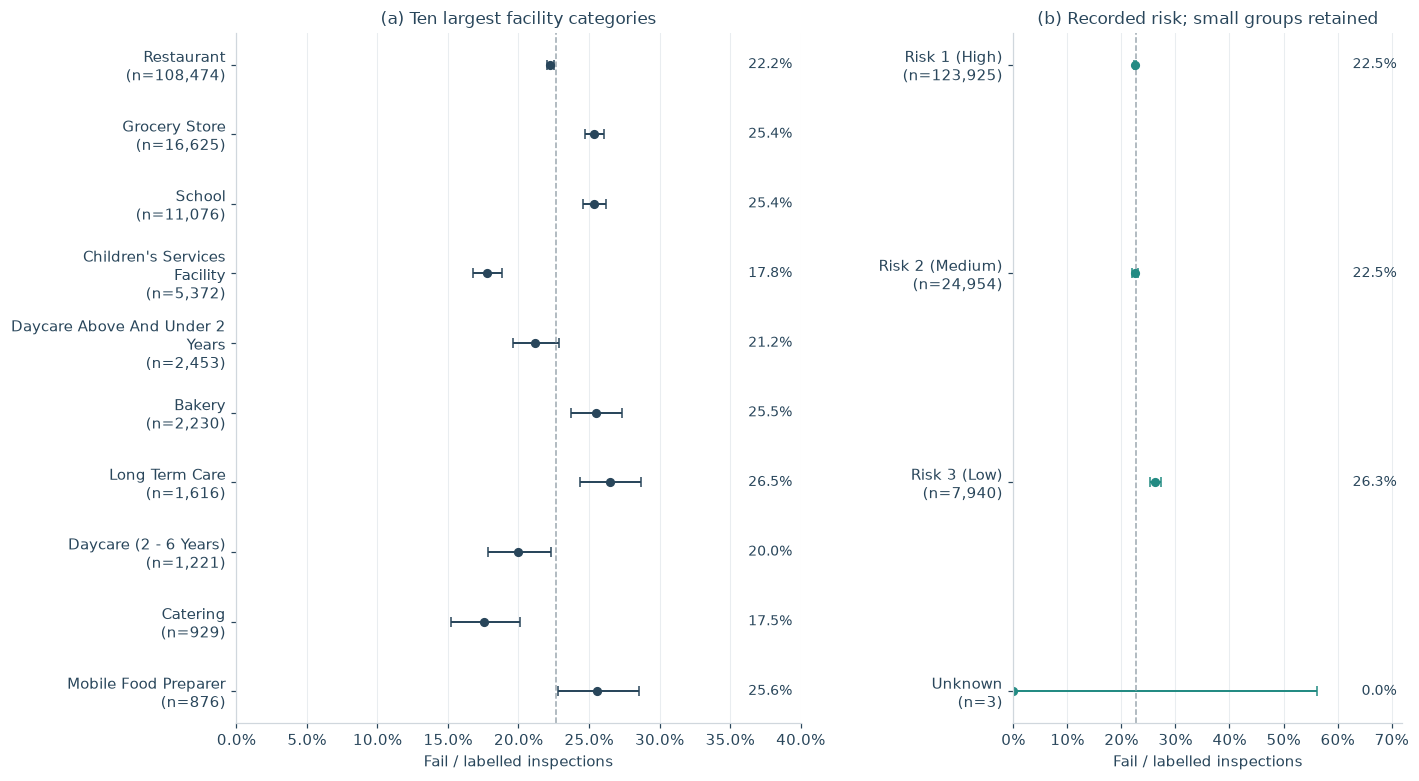

,n,failures,rate,low,high
risk,,,,,
RISK 1 (HIGH),123925,27888,0.225039,2.227228e-01,0.227373
RISK 2 (MEDIUM),24954,5607,0.224693,2.195575e-01,0.229914
RISK 3 (LOW),7940,2085,0.262594,2.530318e-01,0.272387
UNKNOWN,3,0,0.000000,5.551115e-17,0.561497


Ten largest facility types cover 96.21% of labelled development rows.


In [6]:
category_audit = pd.DataFrame([
    {
        "field": original,
        "raw_categories_including_missing": dev_raw[original].nunique(dropna=False),
        "normalized_categories": dev[clean].nunique(dropna=False),
    }
    for original, clean in [("Facility Type", "facility_type"),
                            ("Inspection Type", "inspection_type"), ("City", "city")]
])
save_table(category_audit, "category_audit.csv", index=False)
display(category_audit)
facility_rates = group_rates(labelled, "facility_type").sort_values("n", ascending=False)
risk_rates = group_rates(labelled, "risk").sort_values("n", ascending=False)
save_table(facility_rates, "facility_failure_rates.csv")
save_table(risk_rates, "risk_failure_rates.csv")
top_facilities = facility_rates.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 7.2), gridspec_kw={"width_ratios": [1.45, 1]})
rate_plot(axes[0], top_facilities, color=NAVY, baseline=overall_rate, xmax=.4, wrap=26)
rate_plot(axes[1], risk_rates, color=TEAL, baseline=overall_rate, xmax=.72, wrap=20)
axes[0].set_title("(a) Ten largest facility categories")
axes[1].set_title("(b) Recorded risk; small groups retained")
fig.tight_layout(w_pad=3.5)
save_figure(fig, "04_facilities_and_risk.png")
display(risk_rates)
print(f"Ten largest facility types cover {top_facilities['n'].sum()/len(labelled):.2%} of labelled development rows.")


**Figure 4.** Restaurants account for **108,474 labelled inspections** with a 22.24% Fail rate; grocery stores have 25.36%, and children's services facilities 17.80%. Facility type is a useful candidate feature, while the many rare categories need training-only frequency handling. Minimal normalization reduces **362 raw facility categories to 331**; it does not establish that similarly named categories are the same kind of business.

The risk comparison is not monotonic: the recorded **Low** category has a **26.26%** Fail rate (n=7,940), versus **22.50%** for High (n=123,925). A risk category is not an observed failure probability. Its association may reflect establishment and inspection mix. Risk will be encoded categorically rather than imposing a linear Low-to-High effect. UNKNOWN has only three labelled observations, so its wide interval is not evidence for a stable zero rate. The raw ALL risk category occurs in 57 development records but has no labelled observations.

## 6. Inspection purpose and target availability

**Question:** How much does the reason for the visit affect failure rates and whether a binary judgement exists?

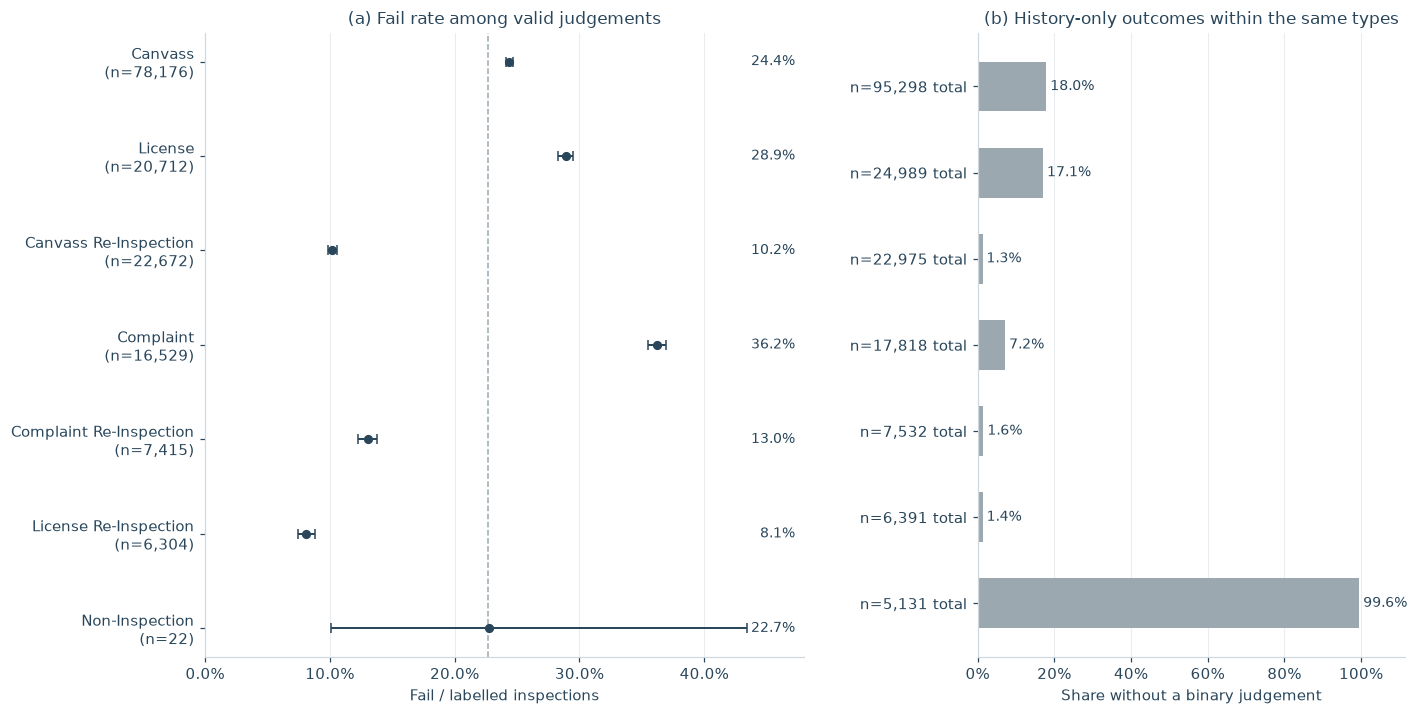

In [7]:
inspection_summary = dev.groupby("inspection_type").agg(
    all_records=("inspection_id", "size"), labelled_records=("label", "count")
)
inspection_summary["unlabelled_share"] = 1-inspection_summary.labelled_records/inspection_summary.all_records
inspection_rates = group_rates(labelled, "inspection_type")
save_table(inspection_summary, "inspection_target_availability.csv")
save_table(inspection_rates, "inspection_failure_rates.csv")
top_types = inspection_summary.sort_values("all_records", ascending=False).head(7).index
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6), gridspec_kw={"width_ratios": [1.4, 1]})
rate_plot(axes[0], inspection_rates.reindex(top_types), color=NAVY, baseline=overall_rate, xmax=.48, wrap=30)
axes[0].set_title("(a) Fail rate among valid judgements")
availability = inspection_summary.reindex(top_types)
y = np.arange(len(top_types))
axes[1].barh(y, availability.unlabelled_share, color=GREY, height=.58)
axes[1].set_yticks(y, [f"n={n:,} total" for n in availability.all_records])
axes[1].invert_yaxis()
for position, share in enumerate(availability.unlabelled_share):
    axes[1].text(share+.01, position, f"{share:.1%}", va="center", fontsize=9)
axes[1].set_xlim(0, max(.5, float(availability.unlabelled_share.max())+.12))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xlabel("Share without a binary judgement")
axes[1].set_title("(b) History-only outcomes within the same types")
axes[1].xaxis.grid(True)
axes[1].set_axisbelow(True)
fig.tight_layout(w_pad=3)
save_figure(fig, "05_inspection_purpose_and_eligibility.png")


**Figure 5.** Complaint inspections have a **36.23%** Fail rate (n=16,529), compared with **24.39%** for CANVASS (n=78,176). CANVASS re-inspections have **10.22%** (n=22,672), and licence re-inspections **8.11%** (n=6,304). Visit purpose is associated with large changes in the target rate and should be included before interpreting store history.

NON-INSPECTION has 5,131 development records but only 22 valid judgements (99.57% are unjudged). Panel (b) uses all records as its denominator, while panel (a) uses only valid judgements. Different rates of No Entry, closure and other non-judgements can affect which records reach the classification task. The model estimates failure conditional on a recorded judgement; it does not predict whether entry will be possible. Inspection purpose is usable only when supplied or known before the visit.

## 7. Differences across areas

**Question:** Do area differences persist when restricting the comparison to a common inspection purpose?

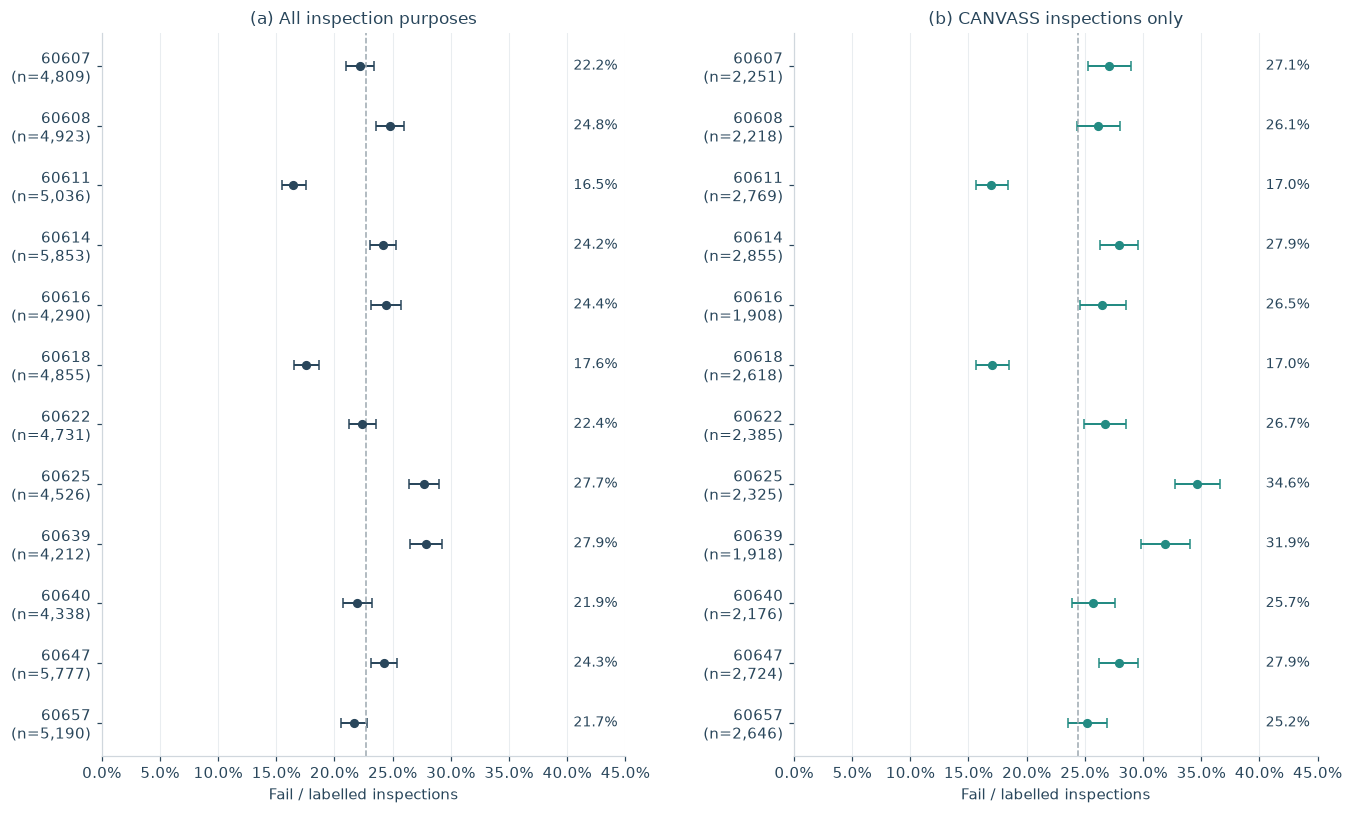

In [8]:
zip_rates = group_rates(labelled, "zip")
canvass = labelled.loc[labelled.inspection_type.eq("CANVASS")].copy()
canvass_zip = group_rates(canvass, "zip")
supported_zips = zip_rates.loc[zip_rates.n.ge(CFG["minimum_zip_count"])]
selected_zips = supported_zips.sort_values("n", ascending=False).head(12).sort_index().index
all_zip_plot = zip_rates.reindex(selected_zips)
canvass_zip_plot = canvass_zip.reindex(selected_zips)
assert canvass_zip_plot.n.ge(100).all()
zip_comparison = all_zip_plot.add_prefix("all_").join(canvass_zip_plot.add_prefix("canvass_"))
save_table(zip_rates, "zip_failure_rates_all.csv")
save_table(zip_comparison, "zip_comparison_selected.csv")
fig, axes = plt.subplots(1, 2, figsize=(12.4, 7.5))
rate_plot(axes[0], all_zip_plot, color=NAVY, baseline=overall_rate, xmax=.45, wrap=10)
rate_plot(axes[1], canvass_zip_plot, color=TEAL, baseline=float(canvass.label.mean()), xmax=.45, wrap=10)
axes[0].set_title("(a) All inspection purposes")
axes[1].set_title("(b) CANVASS inspections only")
fig.tight_layout(w_pad=3.5)
save_figure(fig, "06_zip_comparison.png")


**Figure 6.** ZIPs are selected by sample size, not by their outcome rate: the 12 largest groups among ZIPs with at least 500 labelled development observations. Within these groups, ZIP **60611** has a **16.48%** overall Fail rate (n=5,036), compared with **27.87%** for **60639** (n=4,212). Restricting to CANVASS gives **16.97%** (n=2,769) and **31.91%** (n=1,918), respectively. Inspection purpose alone does not account for this difference.

This restriction does not control establishment type, risk, time or how premises were selected for inspection. ZIP is a candidate predictor, not a causal ranking of neighbourhood food safety. It stays a string, rare/unseen ZIPs need explicit handling, and geographic interpretations must consider address and coordinate quality.

## 8. Repeated establishments and strictly earlier outcomes

**Question:** Does the association with the last known result change when inspection purpose is held constant?

History is constructed by establishment and calendar date. All records on a date are aggregated before shifting. The most recent earlier date with a judgement is labelled Previous non-Fail, Previous Fail, or Mixed previous date. A non-judgement visit increases visit counts but does not overwrite the last valid result. No earlier judgement can also mean history is left-censored at 2016, not that the establishment is new.

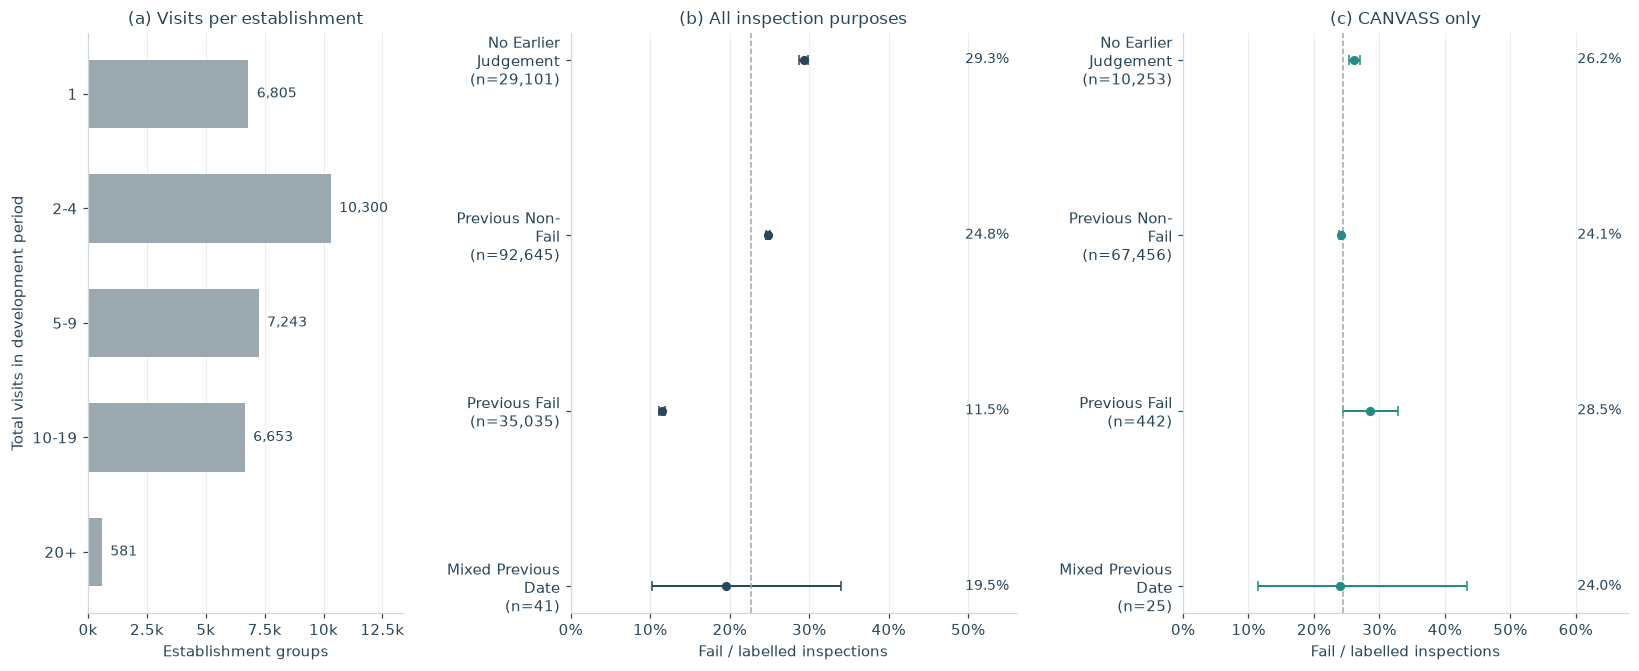

,n,failures,rate,low,high,canvass_n,canvass_failures,canvass_rate,canvass_low,canvass_high
previous_outcome,,,,,,,,,,
No earlier judgement,29101,8528,0.293048,0.287846,0.298305,10253,2685,0.261875,0.253455,0.270473
Previous non-Fail,92645,23021,0.248486,0.245714,0.251279,67456,16251,0.240913,0.237700,0.244154
Previous Fail,35035,4023,0.114828,0.111532,0.118209,442,126,0.285068,0.244974,0.328866
Mixed previous date,41,8,0.195122,0.102344,0.340136,25,6,0.240000,0.114963,0.434297


inspection_type,CANVASS,canvass_share
previous_outcome,,
No earlier judgement,10253,0.352325
Previous non-Fail,67456,0.728113
Previous Fail,442,0.012616
Mixed previous date,25,0.609756


In [9]:
past = strict_past_features(dev)
with_history = labelled.merge(past, on="inspection_id", how="left", validate="one_to_one")
assert with_history[["prior_visits", "prior_judgements", "prior_failures"]].notna().all().all()
history_order = ["No earlier judgement", "Previous non-Fail", "Previous Fail", "Mixed previous date"]
prior_rates = group_rates(with_history, "previous_outcome").reindex(history_order)
prior_canvass = group_rates(
    with_history.loc[with_history.inspection_type.eq("CANVASS")], "previous_outcome"
).reindex(history_order)
save_table(prior_rates, "previous_outcome_rates_all.csv")
save_table(prior_canvass, "previous_outcome_rates_canvass.csv")
history_mix = pd.crosstab(with_history.previous_outcome, with_history.inspection_type)
history_mix["canvass_share"] = history_mix["CANVASS"] / history_mix.sum(axis=1)
save_table(history_mix, "previous_outcome_inspection_mix.csv")

visits = dev.establishment_key.value_counts()
visit_bins = pd.cut(visits, bins=[0, 1, 4, 9, 19, np.inf],
                    labels=["1", "2-4", "5-9", "10-19", "20+"])
visit_distribution = visit_bins.value_counts(sort=False)
save_table(visit_distribution.rename("establishments").to_frame(), "visits_per_establishment.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 6.2),
                         gridspec_kw={"width_ratios": [.85, 1.2, 1.2]})
axes[0].barh(visit_distribution.index.astype(str), visit_distribution.values, color=GREY, height=.6)
axes[0].invert_yaxis()
for y, n in enumerate(visit_distribution):
    axes[0].text(n+visit_distribution.max()*.035, y, f"{n:,}", va="center", fontsize=9)
axes[0].set_xlim(0, visit_distribution.max()*1.3)
axes[0].set_title("(a) Visits per establishment")
axes[0].set_xlabel("Establishment groups")
axes[0].set_ylabel("Total visits in development period")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value/1000:g}k"))
axes[0].xaxis.grid(True)
axes[0].set_axisbelow(True)
rate_plot(axes[1], prior_rates, color=NAVY, baseline=overall_rate, xmax=.56, wrap=16)
rate_plot(axes[2], prior_canvass, color=TEAL, baseline=float(canvass.label.mean()), xmax=.68, wrap=16)
axes[1].set_title("(b) All inspection purposes")
axes[2].set_title("(c) CANVASS only")
fig.tight_layout(w_pad=2.7)
save_figure(fig, "07_repeats_and_prior_outcome.png")
display(prior_rates.join(prior_canvass.add_prefix("canvass_")))
display(history_mix[["CANVASS", "canvass_share"]].reindex(history_order))


**Figure 7.** The development period contains **31,582 establishment groups**, of which **24,777** have repeated inspections. **96.33% of inspection rows** belong to groups that repeat somewhere in this period. These lifetime totals describe the dataset; only strictly earlier visit counts can be used as predictors.

The direction of the history association reverses after restriction. Across all inspection purposes, the current Fail rate is **11.48% after Previous Fail** (n=35,035) and **24.85% after Previous non-Fail** (n=92,645). Among CANVASS inspections, the rates are **28.51%** (n=442) and **24.09%** (n=67,456), respectively. CANVASS forms only **1.26%** of inspections after a previous failure, versus **72.81%** after a previous non-failure. This difference in inspection mix helps explain why the pooled association is misleading.

This is an observed reversal, not evidence that a failure protects a business or that a previous failure causes the next one. The CANVASS-after-Fail subgroup is much smaller. Modelling should compare inspection purpose alone with purpose plus history and their interaction. The descriptive history here updates after earlier dates; evaluation will instead freeze outcome history at each prediction-batch boundary, so these rates are not an estimate of batch prediction performance.

## 9. Evaluation design and known versus unseen establishments

**Question:** What would the proposed later-period evaluation measure?

The split is fixed in config/assessment1.json: training through 2024, validation in 2025, and a local test from January to September 2026. October is an incomplete tail reserved for a later, locked final refit. Only record counts, label eligibility and identity overlap are examined for 2026; no 2026 Fail rate or model score is inspected.

,start,end,all_records,eligible_records,known_records,unseen_records,known_share
period,,,,,,,
Training,2016-01-01,2024-12-31,166065,140762,NaN,NaN,NaN
Validation,2025-01-01,2025-12-31,19205,16060,13701.0,2359.0,0.853113
Local test,2026-01-01,2026-09-30,12382,10515,8965.0,1550.0,0.852592
October tail,2026-10-01,2026-10-30,230,201,NaN,NaN,NaN


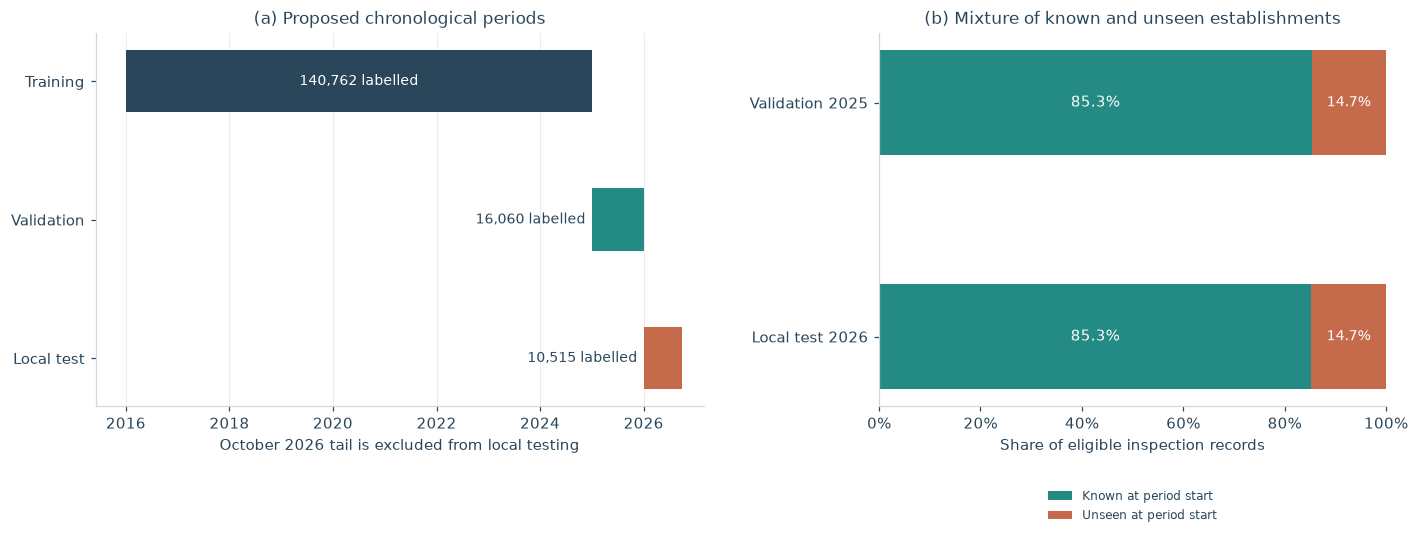

In [10]:
periods = [
    ("Training", "2016-01-01", CFG["train_end"], None),
    ("Validation", CFG["validation_start"], CFG["validation_end"], CFG["train_end"]),
    ("Local test", CFG["local_test_start"], CFG["local_test_end"], CFG["validation_end"]),
    ("October tail", CFG["tail_start"], "2026-10-30", None),
]
split_rows = []
for name, start, end, prior_end in periods:
    frame = history.loc[history.inspection_date.between(start, end)]
    eligible = frame.loc[frame.label.notna()]
    known_keys = set(history.loc[history.inspection_date.le(prior_end), "establishment_key"]) if prior_end else set()
    known_n = int(eligible.establishment_key.isin(known_keys).sum()) if prior_end else None
    split_rows.append({
        "period": name, "start": start, "end": end,
        "all_records": len(frame), "eligible_records": len(eligible),
        "known_records": known_n,
        "unseen_records": len(eligible)-known_n if prior_end else None,
        "known_share": known_n/len(eligible) if prior_end else None,
    })
splits = pd.DataFrame(split_rows).set_index("period")
save_table(splits, "proposed_splits_and_overlap.csv")
assert pd.Timestamp(CFG["train_end"]) < pd.Timestamp(CFG["validation_start"])
assert pd.Timestamp(CFG["validation_end"]) < pd.Timestamp(CFG["local_test_start"])
assert pd.Timestamp(CFG["local_test_end"]) < pd.Timestamp(CFG["tail_start"])
display(splits)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
for y, (name, color) in enumerate(zip(["Training", "Validation", "Local test"], [NAVY, TEAL, RUST])):
    row = splits.loc[name]
    start = mdates.date2num(pd.Timestamp(row["start"]).to_pydatetime())
    end = mdates.date2num((pd.Timestamp(row["end"])+pd.Timedelta(days=1)).to_pydatetime())
    axes[0].barh(y, end-start, left=start, height=.45, color=color)
    if end-start > 500:
        axes[0].text(start+(end-start)*.5, y, f'{row["eligible_records"]:,} labelled',
                     ha="center", va="center", color="white", fontsize=9)
    else:
        axes[0].text(start-45, y, f'{row["eligible_records"]:,} labelled',
                     ha="right", va="center", fontsize=9)
axes[0].set_yticks([0, 1, 2], ["Training", "Validation", "Local test"])
axes[0].invert_yaxis()
axes[0].xaxis_date()
axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_xlim(pd.Timestamp("2015-06-01"), pd.Timestamp("2027-03-01"))
axes[0].set_title("(a) Proposed chronological periods")
axes[0].set_xlabel("October 2026 tail is excluded from local testing")
axes[0].xaxis.grid(True)
axes[0].set_axisbelow(True)
overlap = splits.loc[["Validation", "Local test"]]
positions = np.arange(len(overlap))
known = overlap.known_share.to_numpy(dtype=float)
axes[1].barh(positions, known, color=TEAL, height=.45, label="Known at period start")
axes[1].barh(positions, 1-known, left=known, color=RUST, height=.45, label="Unseen at period start")
axes[1].set_yticks(positions, ["Validation 2025", "Local test 2026"])
axes[1].invert_yaxis()
for y, value in enumerate(known):
    axes[1].text(value/2, y, f"{value:.1%}", ha="center", va="center", color="white")
    axes[1].text(value+(1-value)/2, y, f"{1-value:.1%}", ha="center", va="center", color="white", fontsize=9)
axes[1].set_xlim(0, 1)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xlabel("Share of eligible inspection records")
axes[1].set_title("(b) Mixture of known and unseen establishments")
axes[1].legend(frameon=False, loc="lower center", bbox_to_anchor=(.5, -.34), fontsize=8)
fig.tight_layout(w_pad=3)
save_figure(fig, "08_time_split_and_establishment_overlap.png")


**Figure 8.** The proposed training period has **140,762** eligible records and validation **16,060**. Validation includes **13,701 records (85.31%)** from establishment keys seen in training-era history. After a refit through 2025, the local test contains **10,515 eligible records**, of which **8,965 (85.26%)** have earlier known keys. The primary evaluation therefore measures a mixture dominated by later visits to known establishments, not transfer solely to new businesses.

Known means any earlier record at the start of the period, including a non-judgement visit; it does not guarantee an earlier labelled outcome. Supplementary known/unseen scores and a licence-plus-address sensitivity analysis will expose this distinction. TimeSeriesSplit alone does not isolate groups. The October tail contains only 230 observed records through October 9 and is not a complete month.

## 10. Data-quality evidence and modelling consequences

The table distinguishes observed problems from possible explanations. A plausible cause is not a verified correction. Except where explicitly labelled full snapshot, counts below refer to the 2016-2025 development period.

In [11]:
same_day = dev.groupby(["establishment_key", "inspection_date"]).agg(
    records=("inspection_id", "size"), distinct_labels=("label", "nunique")
)
licence_addresses = (
    dev.loc[dev.license_number.ne("")]
    .groupby("license_number").address.nunique()
)
zero_licences = int(dev_raw["License #"].str.strip().eq("0").fillna(False).sum())
blank_licences = int(dev_raw["License #"].isna().sum())
repeated_keys = visits.loc[visits.gt(1)].index
repeat_row_share = float(dev.establishment_key.isin(repeated_keys).mean())
category_before = int(dev_raw["Facility Type"].nunique(dropna=False))
category_after = int(dev.facility_type.nunique())
quality_rows = [
    (
        "Incomplete temporal coverage",
        f"Full snapshot: {len(raw):,} rows; downloaded {metadata['downloaded_at_utc']}; latest inspection {raw_dates.max().date()}.",
        "Records can be published late or revised; 2026 is a partial year.",
        "Freeze the source version and hash; do not compare partial 2026 volume with full years."
    ),
    (
        "Outcomes without a binary judgement",
        f"{excluded_rows:,}/{len(dev):,} development rows are not Fail, Pass or Pass w/ Conditions.",
        "Closure, readiness or entry issues can prevent a judgement.",
        "Exclude from supervised targets, retain strictly earlier visit history; never relabel as pass."
    ),
    (
        "Outcome-dependent reporting and leakage",
        f"Violations text missing: Pass {violation_gaps.loc['Pass','missing_rate']:.2%}; Fail {violation_gaps.loc['Fail','missing_rate']:.2%}.",
        "The current inspection process produces both the narrative and result.",
        "Exclude current Results, Violations and violations_missing from candidate inputs."
    ),
    (
        "Missing static information",
        f"Facility Type: {missing.loc['Facility Type','missing_count']:,}; Risk: {missing.loc['Risk','missing_count']:,}; coordinate pairs: {missing.loc['Latitude','missing_count']:,}.",
        "Incomplete recording is plausible; missingness need not be random.",
        "Use fixed UNKNOWN categories; fit numeric filling and missing indicators only on training rows."
    ),
    (
        "Invalid establishment identifiers",
        f"{blank_licences:,} blank licences and {zero_licences:,} zero licences in development data.",
        "Missing or placeholder administrative identifiers.",
        "Keep identifiers as strings; do not group every zero/missing licence as one establishment."
    ),
    (
        "Possible identity changes",
        f"{int(licence_addresses.gt(1).sum()):,} licence numbers have more than one normalized address.",
        "Moves, spelling changes, reuse or recording errors are possible.",
        "Treat licence groups as provisional; compare with licence-plus-address grouping."
    ),
    (
        "Legitimate repeated visits versus duplicates",
        f"Full snapshot ID duplicates: {int(raw['Inspection ID'].duplicated().sum()):,}; development repeated groups: {int(visits.gt(1).sum()):,}; {repeat_row_share:.2%} of rows belong to repeated groups.",
        "Inspections recur at the same premises.",
        "Keep repeated visits; use chronological evaluation and report known/unseen establishment results."
    ),
    (
        "Same-day ordering is unknown",
        f"{int(same_day.records.gt(1).sum()):,} establishment-date groups have multiple visits; {int(same_day.distinct_labels.gt(1).sum()):,} have both labels.",
        "Several visits, reporting conventions or conflicting records may explain this.",
        "Aggregate dates before shifting; retain mixed earlier dates explicitly and do not order by ID."
    ),
    (
        "Category inconsistency and long tails",
        f"Facility Type: {category_before} raw categories, {category_after} after minimal normalization. City CCHICAGO appears {int(dev.city.eq('CCHICAGO').sum()):,} times.",
        "Free text permits case variants and spelling errors; some rare values are legitimate.",
        "Normalize whitespace/case; audit aliases; fit rare-category rules on training only."
    ),
    (
        "Location information is not uniformly Chicago-only",
        f"{int(dev.city.ne('CHICAGO').sum()):,} records have a missing or other City; {int(dev.state.eq('').sum()):,} have missing State.",
        "Spelling errors and records outside the city may coexist.",
        "Do not fill every State with IL or silently delete non-Chicago entries; audit before geographical claims."
    ),
    (
        "Recorded risk is not a monotonic outcome score",
        f"Low risk Fail rate: {risk_rates.loc['RISK 3 (LOW)','rate']:.2%}; High: {risk_rates.loc['RISK 1 (HIGH)','rate']:.2%}; UNKNOWN has only {risk_rates.loc['UNKNOWN','n']:,} labelled rows.",
        "Risk category, establishment mix and inspection purpose describe different aspects of the record.",
        "Use categorical risk and examine interactions; do not assume higher category means higher Fail probability."
    ),
    (
        "History is left-censored and procedure-sensitive",
        "Permitted history begins in 2016; saved source metadata flags a 2018-07-01 procedure change.",
        "Earlier visits may exist outside the allowed window; recording practices can change.",
        "Interpret no prior judgement as unavailable history; use forward validation and report period sensitivity."
    ),
]
quality = pd.DataFrame(quality_rows, columns=["problem", "evidence", "possible_reason", "effect_and_action"])
save_table(quality, "data_quality_evidence.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(quality)


,problem,evidence,possible_reason,effect_and_action
0,Incomplete temporal coverage,"Full snapshot: 197,882 rows; downloaded 2026-10-12T07:59:09+00:00; latest inspection 2026-10-09.",Records can be published late or revised; 2026 is a partial year.,Freeze the source version and hash; do not compare partial 2026 volume with full years.
1,Outcomes without a binary judgement,"28,448/185,270 development rows are not Fail, Pass or Pass w/ Conditions.","Closure, readiness or entry issues can prevent a judgement.","Exclude from supervised targets, retain strictly earlier visit history; never relabel as pass."
2,Outcome-dependent reporting and leakage,Violations text missing: Pass 26.38%; Fail 2.40%.,The current inspection process produces both the narrative and result.,"Exclude current Results, Violations and violations_missing from candidate inputs."
3,Missing static information,Facility Type: 894; Risk: 36; coordinate pairs: 633.,Incomplete recording is plausible; missingness need not be random.,Use fixed UNKNOWN categories; fit numeric filling and missing indicators only on training rows.
4,Invalid establishment identifiers,7 blank licences and 418 zero licences in development data.,Missing or placeholder administrative identifiers.,Keep identifiers as strings; do not group every zero/missing licence as one establishment.
5,Possible identity changes,167 licence numbers have more than one normalized address.,"Moves, spelling changes, reuse or recording errors are possible.",Treat licence groups as provisional; compare with licence-plus-address grouping.
6,Legitimate repeated visits versus duplicates,"Full snapshot ID duplicates: 0; development repeated groups: 24,777; 96.33% of rows belong to repeated groups.",Inspections recur at the same premises.,Keep repeated visits; use chronological evaluation and report known/unseen establishment results.
7,Same-day ordering is unknown,"1,292 establishment-date groups have multiple visits; 57 have both labels.","Several visits, reporting conventions or conflicting records may explain this.",Aggregate dates before shifting; retain mixed earlier dates explicitly and do not order by ID.
8,Category inconsistency and long tails,"Facility Type: 362 raw categories, 331 after minimal normalization. City CCHICAGO appears 34 times.",Free text permits case variants and spelling errors; some rare values are legitimate.,Normalize whitespace/case; audit aliases; fit rare-category rules on training only.
9,Location information is not uniformly Chicago-only,339 records have a missing or other City; 64 have missing State.,Spelling errors and records outside the city may coexist.,Do not fill every State with IL or silently delete non-Chicago entries; audit before geographical claims.


These checks support conservative cleaning: keep the raw snapshot, preserve non-judgement visits and repeated inspections, and stop on conflicting duplicate IDs rather than picking an arbitrary row. Missing categories are made explicit; missing geographical fields are not guessed. Statistical transformations and category-frequency decisions belong inside training folds.

The same-day conflicts and licence/address changes limit the precision of historical features and group-based evaluation. Outcomes attach to inspection records, while establishment keys are a matching convention. Neither a repeated licence nor a plausible city spelling proves a verified physical establishment.

In [12]:
availability = pd.DataFrame([
    ("Facility type / Risk / Inspection type", "Conditional", "Candidate",
     "Use only the values supplied or known before the visit; no current-result-derived substitutions."),
    ("ZIP / coordinates / scheduled calendar fields", "Conditional", "Candidate",
     "Validate availability; handle missing/unseen values using training-only processing."),
    ("Inspection ID / licence / names / address", "Conditional", "Metadata and grouping",
     "Match records and build provisional identities; omit raw IDs and names from the initial classifier."),
    ("Strictly earlier visit and outcome history", "Conditional", "Candidate improvement",
     "Use only earlier dates and labels already available at the batch cutoff."),
    ("Current Results / label", "No", "Target only",
     "Never include as a predictor."),
    ("Current Violations and its missingness flag", "No", "Audit only",
     "Both are produced by the current inspection."),
    ("Full-period visit totals", "No", "Descriptive only",
     "They include visits after the row being predicted."),
    ("Hidden-test outcomes", "No", "Forbidden input",
     "Do not query the portal or use hidden outcomes for any feature or tuning."),
], columns=["field_or_feature", "known_before_visit", "role", "rule"])
save_table(availability, "prediction_time_availability.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(availability)


,field_or_feature,known_before_visit,role,rule
0,Facility type / Risk / Inspection type,Conditional,Candidate,Use only the values supplied or known before the visit; no current-result-derived substitutions.
1,ZIP / coordinates / scheduled calendar fields,Conditional,Candidate,Validate availability; handle missing/unseen values using training-only processing.
2,Inspection ID / licence / names / address,Conditional,Metadata and grouping,Match records and build provisional identities; omit raw IDs and names from the initial classifier.
3,Strictly earlier visit and outcome history,Conditional,Candidate improvement,Use only earlier dates and labels already available at the batch cutoff.
4,Current Results / label,No,Target only,Never include as a predictor.
5,Current Violations and its missingness flag,No,Audit only,Both are produced by the current inspection.
6,Full-period visit totals,No,Descriptive only,They include visits after the row being predicted.
7,Hidden-test outcomes,No,Forbidden input,Do not query the portal or use hidden outcomes for any feature or tuning.


## 11. Modelling plan

The plan below is included in full so that this notebook is the Assessment 1 submission. It is also saved as a separate Markdown reference.

### Modelling plan

**Target and baseline.** Predict Fail = 1 against Pass or Pass w/ Conditions = 0. Keep non-judgements only as earlier history. Compare a constant non-Fail reference with regularized Logistic Regression. Use a scikit-learn pipeline with training-only numeric median imputation and missing indicators, and one-hot encoding with unknown-category handling. Baseline inputs are facility type, risk, inspection purpose, ZIP, calendar month/weekday and coordinates. Exclude raw identifiers, names, current Results, Violations and its missingness flag.

**EDA-based improvements.** Encode risk categorically, since its observed rate is not monotonic. Pool categories appearing fewer than 20 times in training. Compare the baseline with strictly earlier visit/judgement counts, failure proportions and last judgement status, retaining missing/mixed history. Compare inspection-purpose-by-history interactions because the pooled previous-failure association reverses within CANVASS. Exclude lifetime visit totals. ZIP associations motivate location features and subgroup error checks, not causal area rankings.

**Time and selection.** Train on 2016-2024 (140,762 eligible rows), validate on 2025 (16,060), and reserve 2026-01-01 to 2026-09-30 (10,515) for one final local evaluation. Exclude the incomplete October tail. Inside training, use expanding folds ending in 2021, 2022 and 2023, validated on 2022, 2023 and 2024. Compare C in {0.1, 1, 10} and class_weight in {None, balanced} by mean Macro-F1 at threshold 0.5. Use 2025 to choose a threshold from 0.10 to 0.80 in steps of 0.05. Lock features, settings and threshold before examining local-test performance. Refit through 2025 for that evaluation; fix random seed 1001.

**History and establishments.** Construct training histories from strictly earlier dates, aggregating each day before shifting. Freeze outcome history before each validation/test batch starts: a batch's labels cannot update another row's features. This matches unavailable hidden-batch outcomes, though annual batches make histories staler than the 28-day hidden period. Earlier unjudged visits still count. Compare provisional licence keys with licence-plus-address keys. Report known/unseen scores using identities observed before the period starts. About 85% of validation/local-test records have known keys, so pooled performance mainly measures returning establishments. TimeSeriesSplit alone does not isolate groups.

**Evaluation and limits.** Report Macro-F1 with labels [0, 1] and zero_division=0, class-specific precision, recall and F1, and a confusion matrix. False negatives miss failing inspections; false positives consume inspection attention on non-failing ones. Inspect errors by year, purpose and known/unseen status without tuning on test outcomes. The local holdout is retrospective: preparation previously checked file-wide label validity, while this EDA excludes its outcome patterns. Selective inspections, identity errors, left-censored histories and the 2018 procedure change limit interpretation.

**Final hidden prediction.** After one-time local assessment and a final lock, refit on saved history available by 2026-10-30. Save the threshold and provenance, then generate integer predictions by Inspection ID from the teaching team's inputs. Never query hidden outcomes. Keep inputs and code available offline.


## 12. Decisions supported by this EDA

| Finding | Decision for the next stage |
|---|---|
| 22.69% Fail among valid development judgements; many records have no judgement | Use Macro-F1 and the specified label mapping; retain unjudged visits only as history. |
| Monthly volume and annual failure rates change | Use time-ordered validation and discuss procedure/reporting shifts. |
| Violations missingness depends on the current outcome | Exclude the current text and its missingness indicator. |
| Low recorded risk has a higher pooled Fail rate than High | Treat risk as categorical and inspect inspection mix. |
| ZIP differences persist within CANVASS | Consider location features with uncertainty and subgroup error checks. |
| The previous-failure association reverses within CANVASS | Compare inspection purpose with purpose-by-history interactions. |
| Most observations repeat establishment keys, with some identity and same-day conflicts | Use strict-date history and report known/unseen and identity-sensitivity results. |

These are feature and evaluation decisions, not claims of predictive improvement. Assessment 2 will test them against the baseline without using hidden outcomes.

In [13]:
assert len(figure_paths) == 8
assert all((FIG / name).is_file() for name in figure_paths)
assert dev["inspection_date"].max() < pd.Timestamp(CFG["local_test_start"])
summary = {
    "snapshot_sha256": metadata["csv_sha256"],
    "source_downloaded_at_utc": metadata["downloaded_at_utc"],
    "actual_full_snapshot_range": [str(raw_dates.min().date()), str(raw_dates.max().date())],
    "development_end": CFG["development_end"],
    "raw_rows": len(raw), "development_rows": len(dev),
    "labelled_development_rows": len(labelled), "development_failures": int(labelled.label.sum()),
    "development_fail_rate": overall_rate,
    "development_history_only_rows": excluded_rows,
    "constant_nonfail_development_macro_f1": always_nonfail_macro_f1,
    "same_day_conflicting_groups": int(same_day.distinct_labels.gt(1).sum()),
    "previous_outcome_all": prior_rates[["n", "failures", "rate"]].to_dict(orient="index"),
    "previous_outcome_canvass": prior_canvass[["n", "failures", "rate"]].to_dict(orient="index"),
    "figure_files": figure_paths,
    "local_test_outcome_analysis": "not performed",
    "model_training": "not performed; Assessment 1 modelling plan only",
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print(f"Completed: {len(figure_paths)} figures, {len(quality)} data-quality findings, "
      f"an embedded modelling plan and {len(list(OUT.glob('*.csv')))} supporting tables.")


Completed: 8 figures, 12 data-quality findings, an embedded modelling plan and 22 supporting tables.


## Sources and reproducibility

- [Course project brief](../docs/DSAA1001_Project.pdf), especially sections 8 and 10: Assessment 1 deliverables and evaluation requirements.
- [City of Chicago Food Inspections](https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5): original dataset. The notebook reads the saved snapshot rather than the live portal.
- [Saved download metadata](../data/raw/download_metadata.json) and [saved source metadata](../data/raw/source_metadata.json): source, download time, actual coverage and the procedure-change note.
- [AI usage record](../AI-USAGE.md): OpenAI Codex assisted with code, analysis drafting and verification. Group members remain responsible for understanding and explaining the submission.

All figures and tables are calculated from the frozen snapshot. No external data, network request, model fit or hidden-test labels are used by this notebook. The long raw Violations text is retained in the repository for provenance but is not a prediction feature.